In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.linear_model import LogisticRegression


from pathlib import Path

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [22]:
# Main folder path
path = Path(r"E:\LPU\Third Year\SEM5\Predictive Analysis\archive (2)")

# Load both datasets
stocks = pd.read_csv(path / "all_stocks_5yr.csv")
companies = pd.read_csv(path / "sp500_companies.csv")

# Display initial records
print("Stock dataset:", stocks.shape)
print("Company dataset:", companies.shape)

display(stocks.head())
display(companies.head())

Stock dataset: (619040, 7)
Company dataset: (503, 16)


,date,open,high,low,close,volume,Name
0,2013-02-08,15.07,15.12,14.63,14.75,8407500,AAL
1,2013-02-11,14.89,15.01,14.26,14.46,8882000,AAL
2,2013-02-12,14.45,14.51,14.10,14.27,8126000,AAL
3,2013-02-13,14.30,14.94,14.25,14.66,10259500,AAL
4,2013-02-14,14.94,14.96,13.16,13.99,31879900,AAL


,Symbol,Security,Company_ID,GICS_Sector,GICS_Sub_Industry,Headquarters,HQ_City,HQ_State,Date_Added,Founded_Year,Employees,Employees_Year,CEO,Website,CIK,Company_URL
0,A,Agilent Technologies,Q393762,Health Care,Life Sciences Tools & Services,"Santa Clara, California",Santa Clara,California,2000-06-05,1999,17671.0,2023.0,Padraig McDonnell,http://www.agilent.com,1090872,https://en.wikipedia.org/wiki/Agilent_Technolo...
1,AAPL,Apple Inc.,Q312,Information Technology,"Technology Hardware, Storage & Peripherals","Cupertino, California",Cupertino,California,1982-11-30,1977,164000.0,2022.0,John Ternus,https://apple.com/,320193,https://en.wikipedia.org/wiki/Apple_Inc.
2,ABBV,AbbVie,Q14662364,Health Care,Biotechnology,"North Chicago, Illinois",North Chicago,Illinois,2012-12-31,2013,NaN,NaN,Robert A. Michael; Richard A. Gonzalez,http://www.abbvie.com,1551152,https://en.wikipedia.org/wiki/AbbVie
3,ABNB,Airbnb,Q63327,Consumer Discretionary,"Hotels, Resorts & Cruise Lines","San Francisco , California",San Francisco,California,2023-09-18,2008,5597.0,2020.0,Brian Chesky,https://www.airbnb.com/,1559720,https://en.wikipedia.org/wiki/Airbnb
4,ABT,Abbott Laboratories,Q306764,Health Care,Health Care Equipment,"North Chicago, Illinois",North Chicago,Illinois,1957-03-04,1888,73000.0,2015.0,Miles D. White; Robert Ford,https://abbott.com,1800,https://en.wikipedia.org/wiki/Abbott_Laboratories


In [23]:
# Rename columns in the company dataset
company_info = companies.rename(columns={
    "Symbol": "Ticker",
    "Security": "Company_Name",
    "GICS_Sector": "Sector",
    "GICS_Sub_Industry": "Industry"
})

# Standardize ticker symbols
stocks["Ticker"] = stocks["Name"].astype(str).str.strip().str.upper()
company_info["Ticker"] = company_info["Ticker"].astype(str).str.strip().str.upper()

# Select useful company information
company_info = company_info[
    ["Ticker", "Company_Name", "Sector", "Industry"]
]

# Merge both datasets
df = pd.merge(
    stocks.drop(columns=["Name"]),
    company_info,
    on="Ticker",
    how="left"
)

# Preserve unmatched company names using their ticker symbols
df["Company_Name"] = df["Company_Name"].fillna(df["Ticker"])

# Convert date to datetime
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Remove duplicate records
df.drop_duplicates(subset=["date", "Ticker"], inplace=True)

# Remove rows without essential data
df.dropna(subset=["date", "close", "Ticker"], inplace=True)

# Sort data
df.sort_values(["Ticker", "date"], inplace=True)
df.reset_index(drop=True, inplace=True)

print("Final dataset shape:", df.shape)
print("Total companies:", df["Ticker"].nunique())
print("Unmatched companies:", df.loc[df["Sector"].isna(), "Ticker"].nunique())

display(df.head())

Final dataset shape: (619040, 10)
Total companies: 505
Unmatched companies: 152


,date,open,high,low,close,volume,Ticker,Company_Name,Sector,Industry
0,2013-02-08,45.07,45.35,45.00,45.08,1824755,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
1,2013-02-11,45.17,45.18,44.45,44.60,2915405,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
2,2013-02-12,44.81,44.95,44.50,44.62,2373731,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
3,2013-02-13,44.81,45.24,44.68,44.75,2052338,A,Agilent Technologies,Health Care,Life Sciences Tools & Services
4,2013-02-14,44.72,44.78,44.36,44.58,3826245,A,Agilent Technologies,Health Care,Life Sciences Tools & Services


In [24]:
print("Total records:", len(df))
print("Unique companies:", df["Ticker"].nunique())

print("Starting date:", df["date"].min())
print("Ending date:", df["date"].max())

print("\nMissing values:")
display(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

Total records: 619040
Unique companies: 505
Starting date: 2013-02-08 00:00:00
Ending date: 2018-02-07 00:00:00

Missing values:


date                 0
open                11
high                 8
low                  8
close                0
volume               0
Ticker               0
Company_Name         0
Sector          181963
Industry        181963
dtype: int64


Statistical summary:


,date,open,high,low,close,volume
count,619040,619029.000000,619032.000000,619032.000000,619040.000000,6.190400e+05
mean,2015-08-18 00:48:23.494443264,83.023334,83.778311,82.256096,83.043763,4.321823e+06
min,2013-02-08 00:00:00,1.620000,1.690000,1.500000,1.590000,0.000000e+00
25%,2014-05-20 00:00:00,40.220000,40.620000,39.830000,40.245000,1.070320e+06
50%,2015-08-21 00:00:00,62.590000,63.150000,62.020000,62.620000,2.082094e+06
75%,2016-11-15 00:00:00,94.370000,95.180000,93.540000,94.410000,4.284509e+06
max,2018-02-07 00:00:00,2044.000000,2067.990000,2035.110000,2049.000000,6.182376e+08
std,NaN,97.378769,98.207519,96.507421,97.389748,8.693610e+06


### Top 10 companies by average stock price ###

,Ticker,Company_Name,close
0,PCLN,PCLN,1312.873538
1,GOOG,Alphabet Inc. (Class C),725.403353
2,GOOGL,Alphabet Inc. (Class A),682.233847
3,AZO,AutoZone,619.703654
4,AMZN,Amazon,576.880041
5,CMG,Chipotle Mexican Grill,493.256008
6,REGN,Regeneron Pharmaceuticals,381.833100
7,MTD,Mettler Toledo,356.297498
8,BLK,BlackRock,348.628967
9,BIIB,Biogen,295.413264


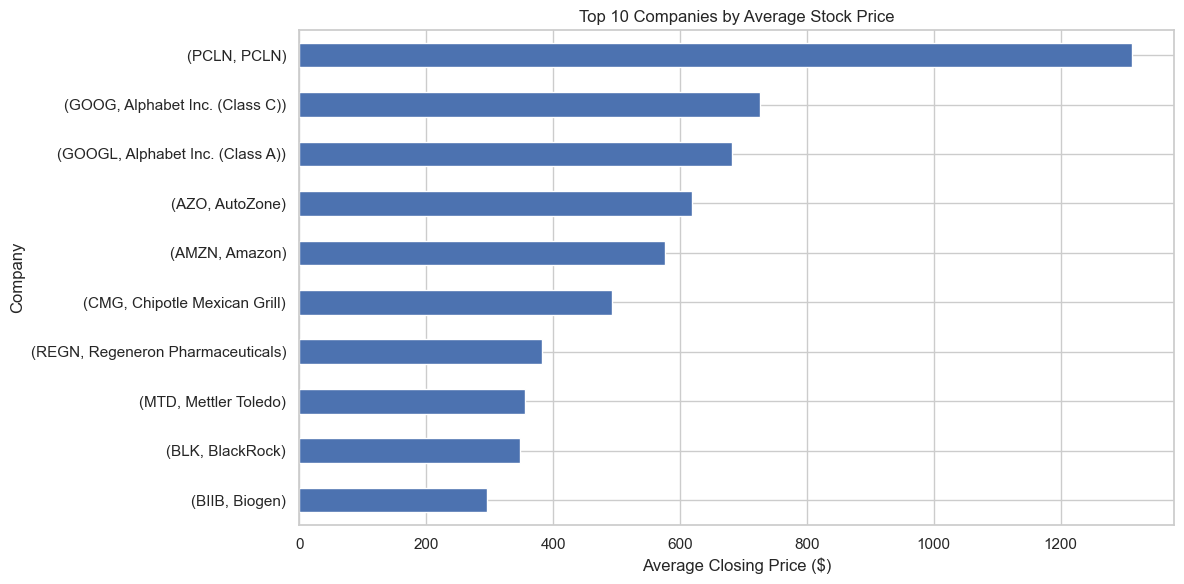

In [25]:
top_prices = (
    df.groupby(["Ticker", "Company_Name"])["close"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

display(top_prices.reset_index())

top_prices.sort_values().plot(kind="barh")

plt.title("Top 10 Companies by Average Stock Price")
plt.xlabel("Average Closing Price ($)")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

### Top 10 companies by trading volume ###

,Ticker,Company_Name,volume
0,BAC,Bank of America,9.363380e+07
1,AAPL,Apple Inc.,5.404790e+07
2,GE,GE Aerospace,4.211568e+07
3,F,Ford Motor Company,3.446237e+07
4,FB,FB,3.435927e+07
5,MSFT,Microsoft,3.386946e+07
6,AMD,Advanced Micro Devices,3.251904e+07
7,MU,Micron Technology,3.024841e+07
8,INTC,Intel,2.932671e+07
9,CSCO,Cisco,2.865435e+07


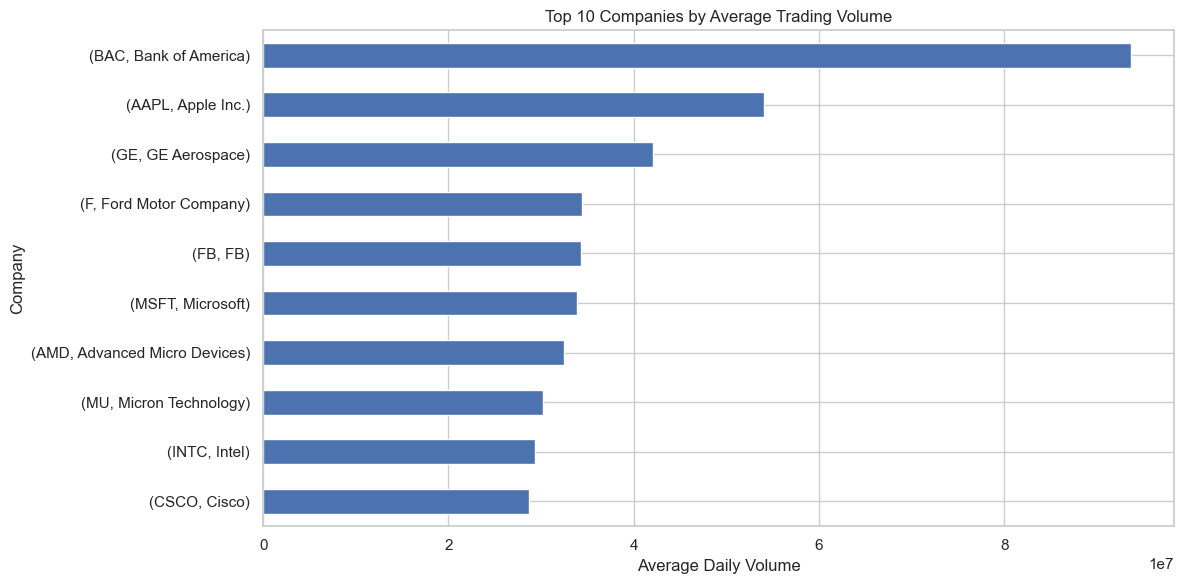

In [26]:
top_volume = (
    df.groupby(["Ticker", "Company_Name"])["volume"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

display(top_volume.reset_index())

top_volume.sort_values().plot(kind="barh")

plt.title("Top 10 Companies by Average Trading Volume")
plt.xlabel("Average Daily Volume")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

### Historical returns and risk analysis ###

### Calculate daily and cumulative returns ###

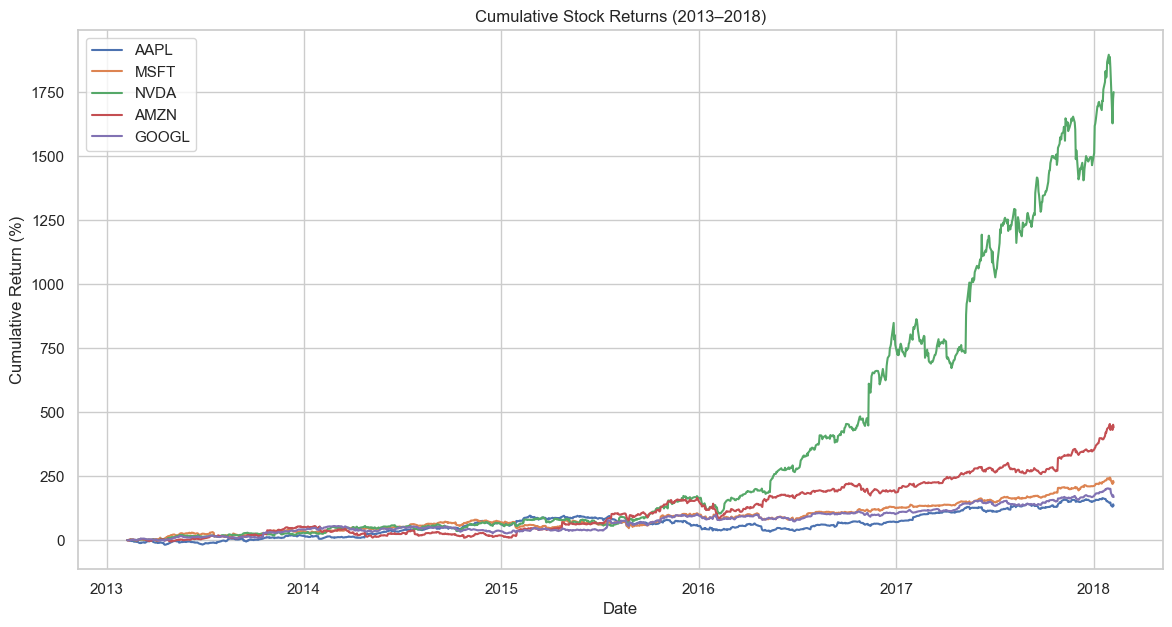

In [27]:
# Calculate daily percentage returns
df["Daily_Return"] = (
    df.groupby("Ticker")["close"]
    .pct_change() * 100
)

# Calculate cumulative returns
df["Cumulative_Return"] = (
    df.groupby("Ticker")["Daily_Return"]
    .transform(
        lambda x: (
            (1 + x.fillna(0) / 100).cumprod() - 1
        ) * 100
    )
)

# Select some familiar companies
selected = ["AAPL", "MSFT", "NVDA", "AMZN", "GOOGL"]

plt.figure(figsize=(14, 7))

for ticker in selected:

    temp = df[df["Ticker"] == ticker]

    if not temp.empty:
        plt.plot(
            temp["date"],
            temp["Cumulative_Return"],
            label=ticker
        )

plt.title("Cumulative Stock Returns (2013–2018)")
plt.xlabel("Date")
plt.ylabel("Cumulative Return (%)")
plt.legend()

plt.show()

### Identify the highest-return companies ###

,Ticker,Company_Name,Total_Return
346,NVDA,Nvidia,1749.636217
334,NFLX,Netflix,923.332096
26,ALGN,Align Technology,615.948671
153,EA,EA,608.405296
427,STZ,Constellation Brands,572.370487
53,AVGO,Broadcom,572.083805
180,FB,FB,531.213873
326,MU,Micron Technology,442.064516
38,AMZN,Amazon,440.858943
51,ATVI,ATVI,417.971663


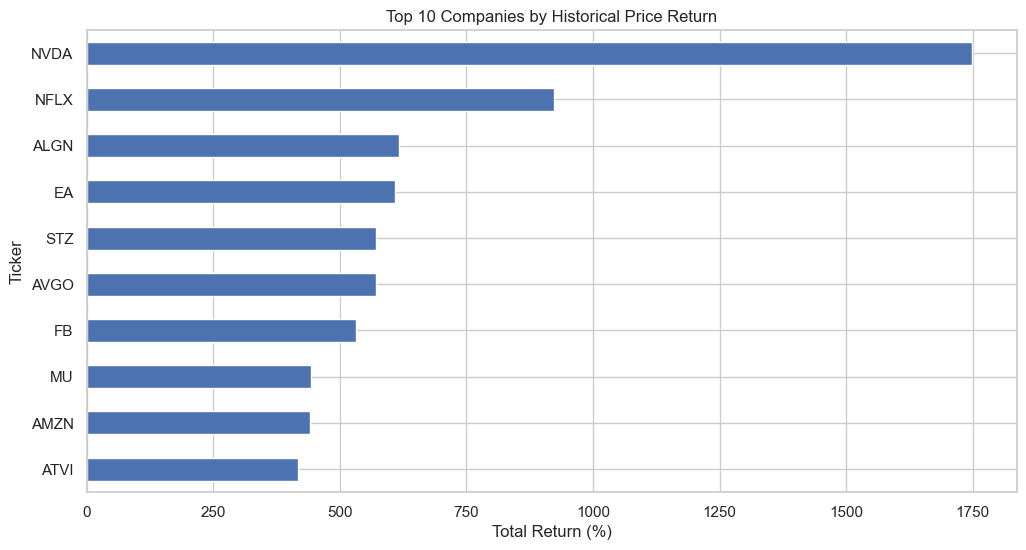

In [28]:
performance = df.groupby(
    ["Ticker", "Company_Name"]
).agg(
    First_Price=("close", "first"),
    Last_Price=("close", "last"),
    Trading_Days=("close", "count")
).reset_index()

performance["Total_Return"] = (
    (performance["Last_Price"] / performance["First_Price"]) - 1
) * 100

# Rank companies by total price return
top_performers = performance.nlargest(10, "Total_Return")

display(
    top_performers[
        ["Ticker", "Company_Name", "Total_Return"]
    ]
)

top_performers.sort_values("Total_Return").plot(
    x="Ticker",
    y="Total_Return",
    kind="barh",
    legend=False
)

plt.title("Top 10 Companies by Historical Price Return")
plt.xlabel("Total Return (%)")
plt.show()

### Identify the most volatile companies ###

,Ticker,Company_Name,Daily_Volatility,Annualized_Volatility
95,CHK,CHK,4.165753,66.129285
32,AMD,Advanced Micro Devices,3.778425,59.980643
68,BHGE,BHGE,3.521895,55.908352
182,FCX,Freeport-McMoRan,3.412276,54.168197
288,LNT,Alliant Energy,3.337309,52.978144
475,VRTX,Vertex Pharmaceuticals,3.210302,50.961971
245,INCY,Incyte,2.977661,47.268903
320,MRO,MRO,2.973891,47.209051
486,WMB,Williams Companies,2.955939,46.924080
453,UA,UA,2.859555,45.394026


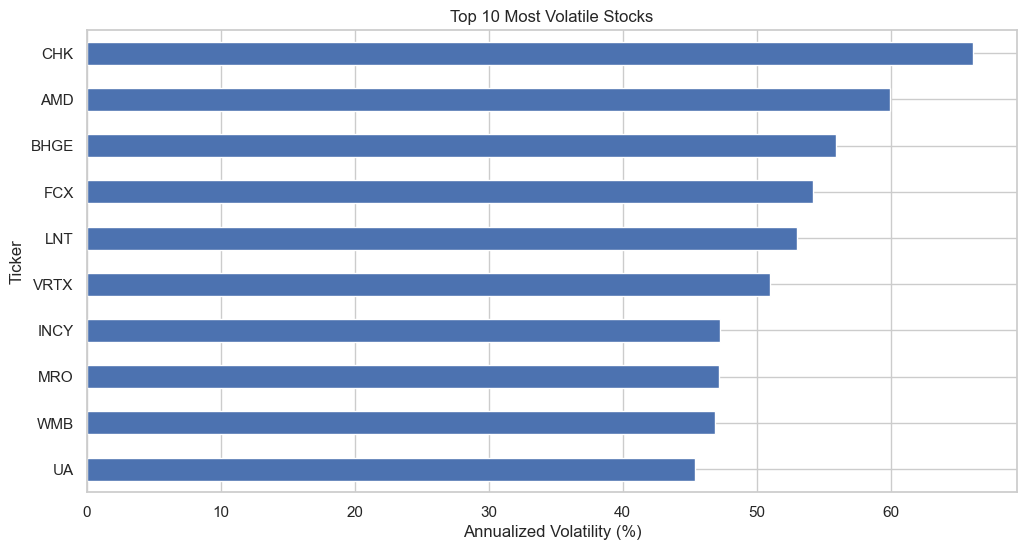

In [29]:
volatility = df.groupby(
    ["Ticker", "Company_Name"]
).agg(
    Daily_Volatility=("Daily_Return", "std")
).reset_index()

volatility["Annualized_Volatility"] = (
    volatility["Daily_Volatility"] * np.sqrt(252)
)

top_risk = volatility.nlargest(
    10, "Annualized_Volatility"
)

display(top_risk)

top_risk.sort_values("Annualized_Volatility").plot(
    x="Ticker",
    y="Annualized_Volatility",
    kind="barh",
    legend=False
)

plt.title("Top 10 Most Volatile Stocks")
plt.xlabel("Annualized Volatility (%)")
plt.show()

### Risk versus return comparison ###

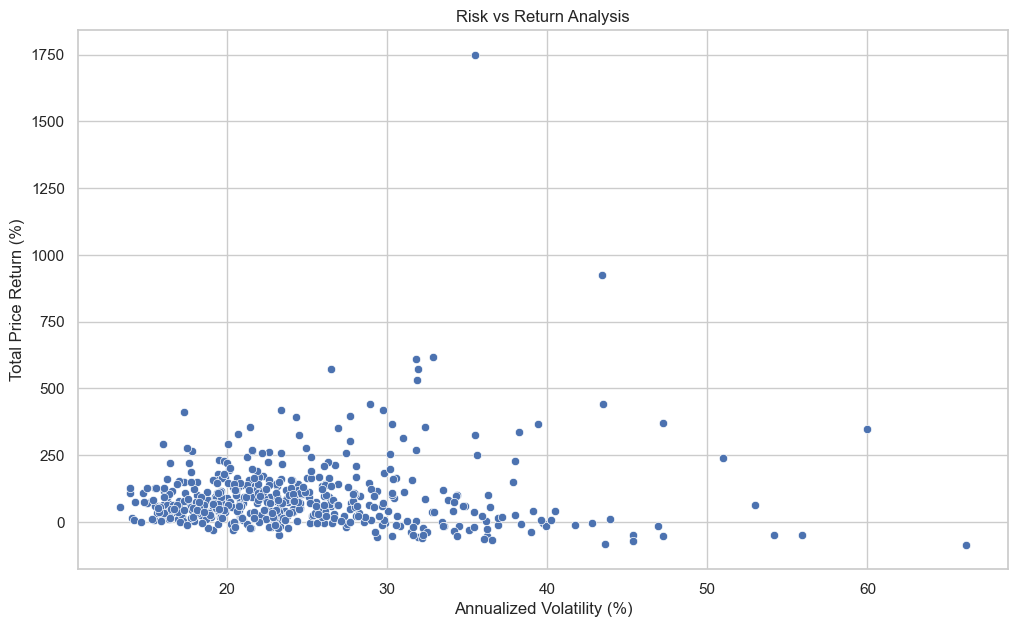

In [30]:
risk_return = pd.merge(
    performance[["Ticker", "Company_Name", "Total_Return"]],
    volatility[["Ticker", "Annualized_Volatility"]],
    on="Ticker"
)

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=risk_return,
    x="Annualized_Volatility",
    y="Total_Return"
)

plt.title("Risk vs Return Analysis")
plt.xlabel("Annualized Volatility (%)")
plt.ylabel("Total Price Return (%)")

plt.show()

### Maximum historical drawdown ###

,Ticker,Company_Name,Maximum_Drawdown
95,CHK,CHK,-94.920128
182,FCX,Freeport-McMoRan,-90.420082
403,RRC,RRC,-86.019210
320,MRO,MRO,-83.857040
138,DISCA,DISCA,-82.003095
139,DISCK,DISCK,-81.843044
486,WMB,Williams Companies,-81.662833
492,WYNN,Wynn Resorts,-79.229683
454,UAA,UAA,-77.694524
453,UA,UA,-76.842335


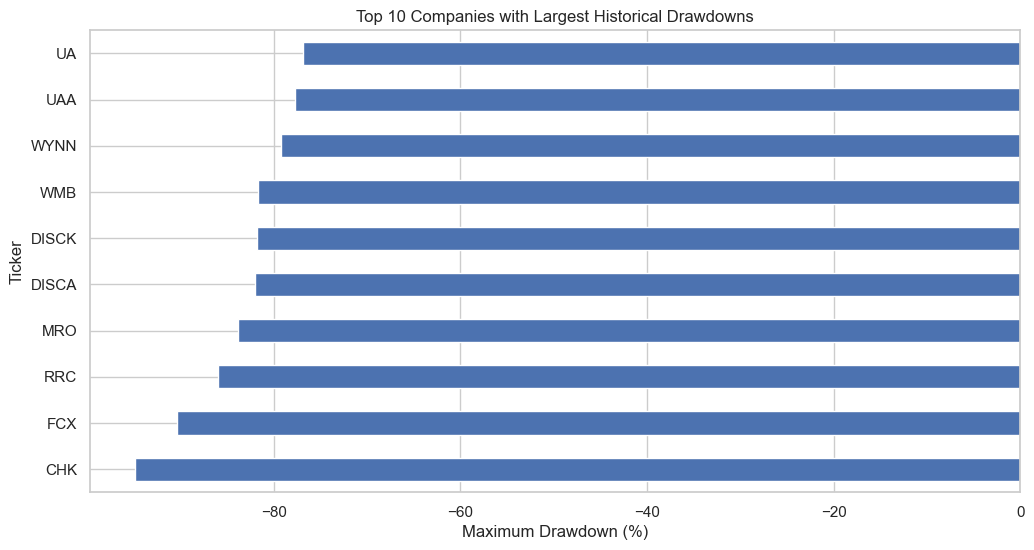

In [31]:
# Calculate cumulative wealth starting from 1
df["Wealth_Index"] = (
    df.groupby("Ticker")["Daily_Return"]
    .transform(
        lambda x: (1 + x.fillna(0) / 100).cumprod()
    )
)

# Calculate running maximum
df["Running_Peak"] = (
    df.groupby("Ticker")["Wealth_Index"].cummax()
)

# Calculate drawdown
df["Drawdown"] = (
    (df["Wealth_Index"] / df["Running_Peak"]) - 1
) * 100

# Find worst drawdown for each company
drawdowns = df.groupby(
    ["Ticker", "Company_Name"]
)["Drawdown"].min().reset_index()

drawdowns.rename(
    columns={"Drawdown": "Maximum_Drawdown"},
    inplace=True
)

worst_drawdowns = drawdowns.nsmallest(
    10, "Maximum_Drawdown"
)

display(worst_drawdowns)

worst_drawdowns.sort_values("Maximum_Drawdown").plot(
    x="Ticker",
    y="Maximum_Drawdown",
    kind="barh",
    legend=False
)

plt.title("Top 10 Companies with Largest Historical Drawdowns")
plt.xlabel("Maximum Drawdown (%)")
plt.show()

### Sector-wise analysis ###

### Compare sector performance ###

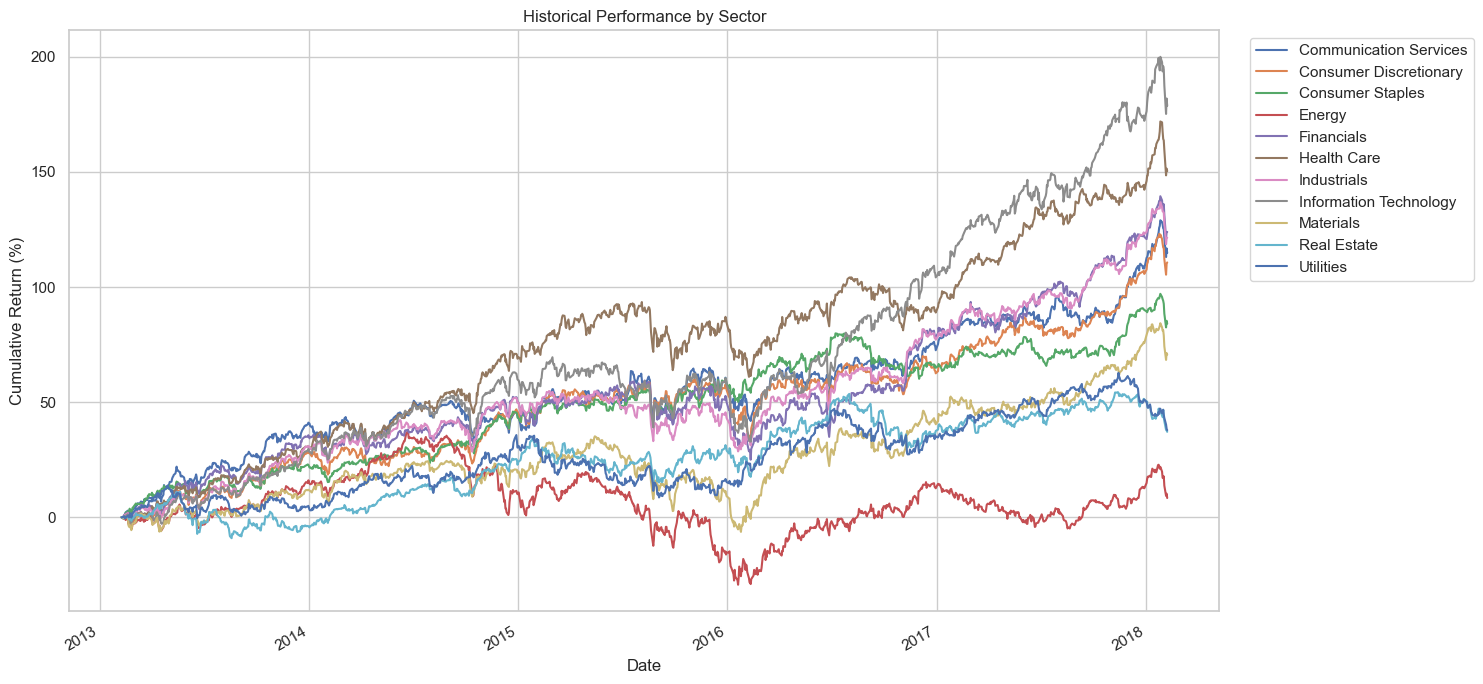

In [32]:
# Calculate average daily return for each sector on each date
sector_daily = df.groupby(
    ["date", "Sector"]
)["Daily_Return"].mean().reset_index()

# Convert sector data into columns
sector_returns = sector_daily.pivot(
    index="date",
    columns="Sector",
    values="Daily_Return"
)

# Calculate compounded sector performance
sector_growth = (
    (1 + sector_returns.fillna(0) / 100).cumprod() - 1
) * 100

# Plot sector performance
sector_growth.plot(figsize=(15, 7))

plt.title("Historical Performance by Sector")
plt.xlabel("Date")
plt.ylabel("Cumulative Return (%)")
plt.legend(bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

### Rank the best and worst sectors ###

BEST PERFORMING SECTORS


Sector
Information Technology    178.671136
Health Care               150.353677
Financials                123.928589
Industrials               121.428812
Communication Services    114.799982
Name: 2018-02-07 00:00:00, dtype: float64

WORST PERFORMING SECTORS


Sector
Consumer Staples    84.142327
Materials           70.692389
Utilities           37.823463
Real Estate         37.128750
Energy               8.397544
Name: 2018-02-07 00:00:00, dtype: float64

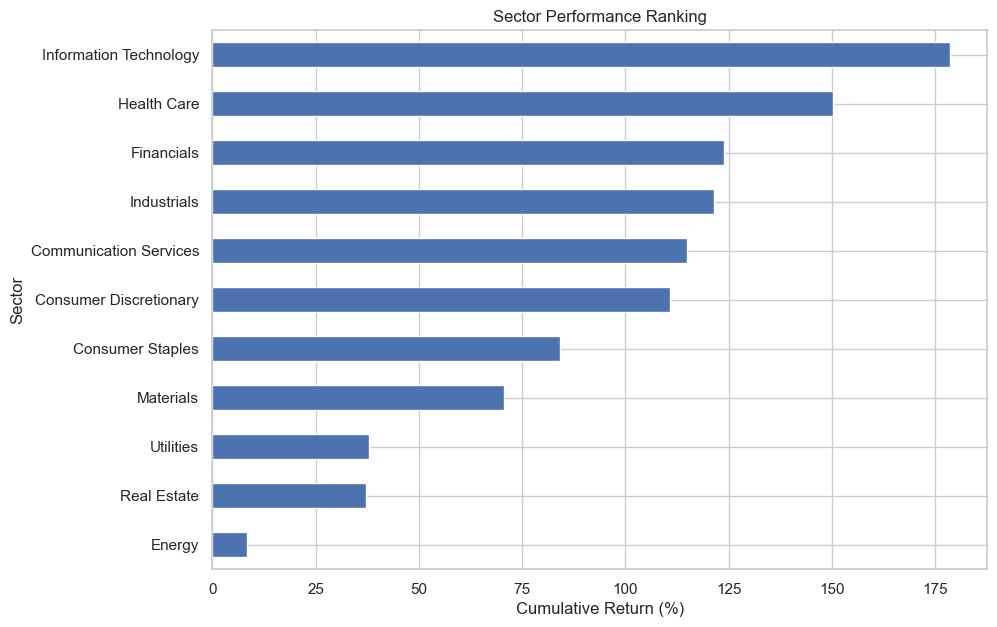

In [33]:
# Calculate final cumulative return for each sector
sector_ranking = sector_growth.iloc[-1].sort_values(
    ascending=False
)

print("BEST PERFORMING SECTORS")
display(sector_ranking.head(5))

print("WORST PERFORMING SECTORS")
display(sector_ranking.tail(5))

sector_ranking.sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Sector Performance Ranking")
plt.xlabel("Cumulative Return (%)")
plt.show()

### Stock relationships ###
### Correlation between companies ###

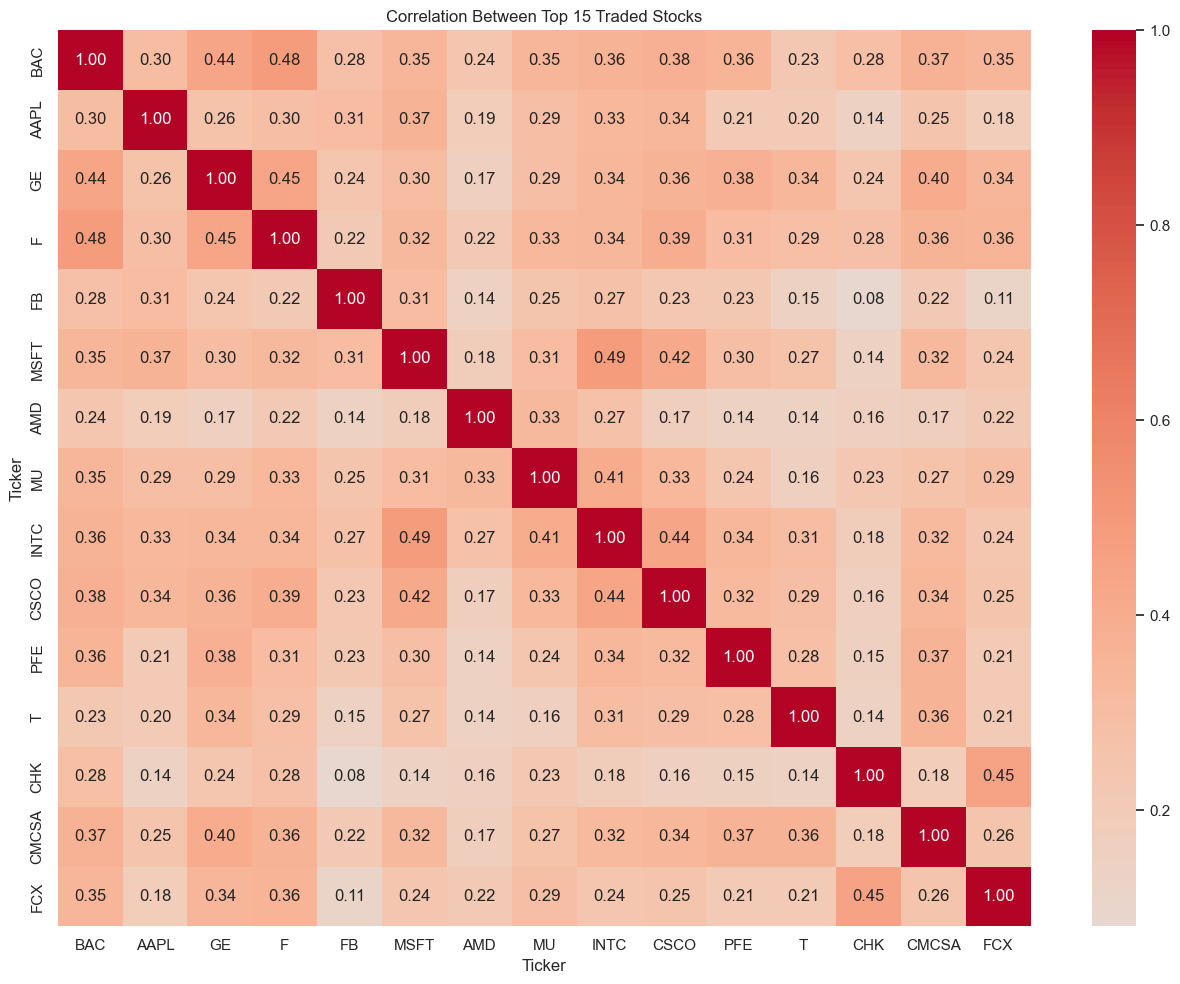

In [34]:
# Create a date-wise stock return table
returns = df.pivot_table(
    index="date",
    columns="Ticker",
    values="Daily_Return"
)

# Select 15 companies with the highest average trading volume
top_15 = (
    df.groupby("Ticker")["volume"]
    .mean()
    .nlargest(15)
    .index
)

# Calculate correlation
correlation = returns[top_15].corr()

# Visualize
plt.figure(figsize=(13, 10))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlation Between Top 15 Traded Stocks")
plt.tight_layout()
plt.show()

## Monthly market performance ##

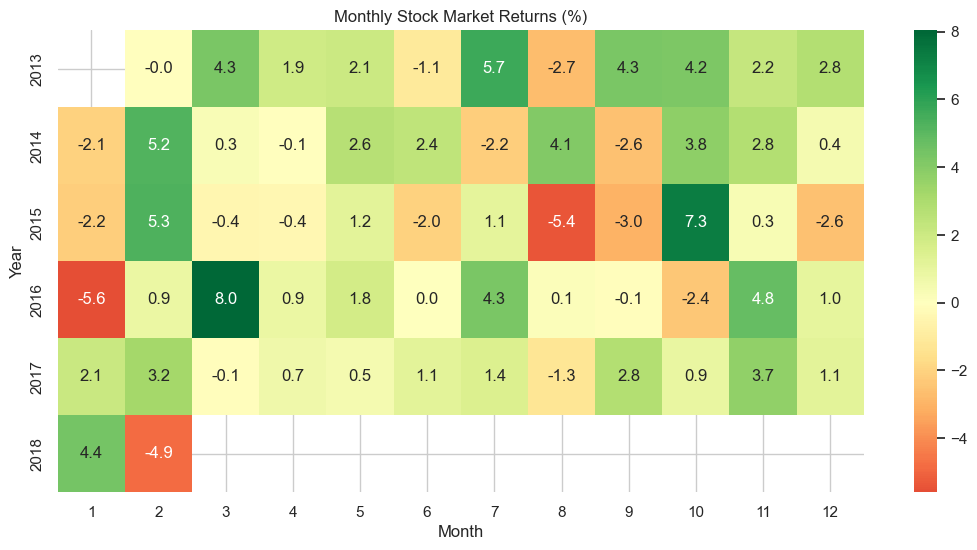

In [35]:
# Calculate average daily return across all available stocks
market_daily = df.groupby("date")["Daily_Return"].mean()

# Convert daily returns into monthly returns
monthly_returns = (
    (1 + market_daily / 100)
    .resample("ME")
    .prod()
    .sub(1) * 100
)

# Create year and month columns
monthly_data = monthly_returns.to_frame(
    name="Monthly_Return"
)

monthly_data["Year"] = monthly_data.index.year
monthly_data["Month"] = monthly_data.index.month

# Create monthly performance table
monthly_pivot = monthly_data.pivot(
    index="Year",
    columns="Month",
    values="Monthly_Return"
)

# Plot heatmap
plt.figure(figsize=(13, 6))

sns.heatmap(
    monthly_pivot,
    annot=True,
    fmt=".1f",
    cmap="RdYlGn",
    center=0
)

plt.title("Monthly Stock Market Returns (%)")
plt.xlabel("Month")
plt.ylabel("Year")

plt.show()

### Group companies using K-Means ###

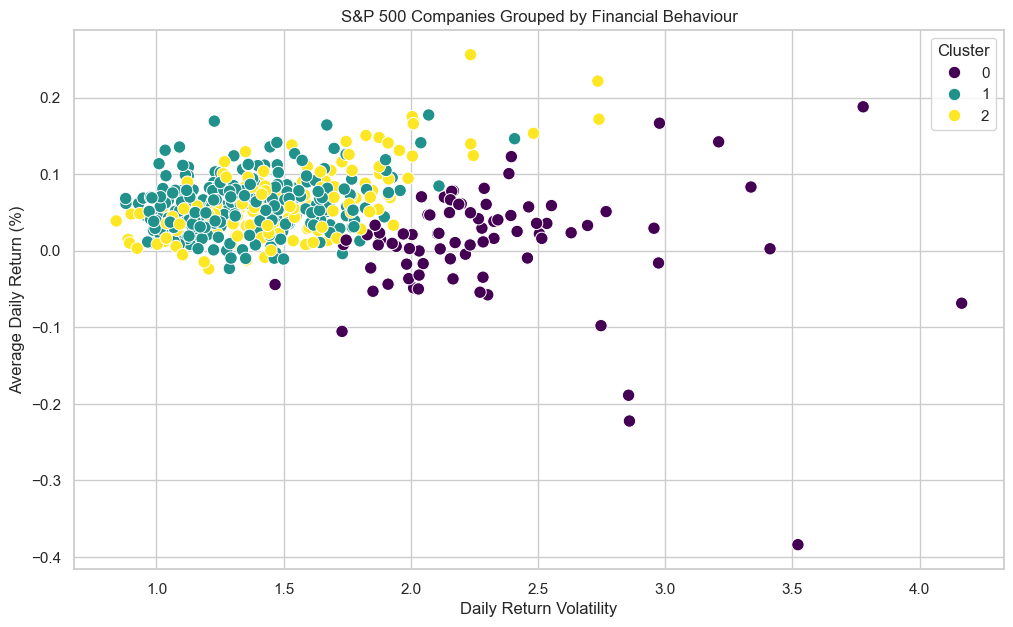

In [37]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Create company-level statistics
company_profile = df.groupby("Ticker").agg(
    Company_Name=("Company_Name", "first"),
    Average_Return=("Daily_Return", "mean"),
    Volatility=("Daily_Return", "std"),
    Average_Volume=("volume", "mean")
).dropna()

# Log transformation of volume
company_profile["Log_Volume"] = np.log1p(
    company_profile["Average_Volume"]
)

# Select features
X = company_profile[
    ["Average_Return", "Volatility", "Log_Volume"]
]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

company_profile["Cluster"] = kmeans.fit_predict(
    X_scaled
)

# Visualize clusters
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=company_profile,
    x="Volatility",
    y="Average_Return",
    hue="Cluster",
    palette="viridis",
    s=80
)

plt.title("S&P 500 Companies Grouped by Financial Behaviour")
plt.xlabel("Daily Return Volatility")
plt.ylabel("Average Daily Return (%)")

plt.show()

Cell 19: Understand the clusters
Compare the average financial characteristics of each group.

In [38]:
cluster_summary = company_profile.groupby(
    "Cluster"
).agg(
    Number_of_Companies=("Company_Name", "count"),
    Average_Return=("Average_Return", "mean"),
    Average_Volatility=("Volatility", "mean"),
    Average_Volume=("Average_Volume", "mean")
)

display(cluster_summary)

,Number_of_Companies,Average_Return,Average_Volatility,Average_Volume
Cluster,,,,
0,80,0.010526,2.321167,4.612002e+06
1,271,0.058915,1.341127,1.538271e+06
2,154,0.064219,1.504065,9.026092e+06


Cell 20: Find the appropriate number of clusters
Use the Elbow Method to investigate how many company groups are suitable.

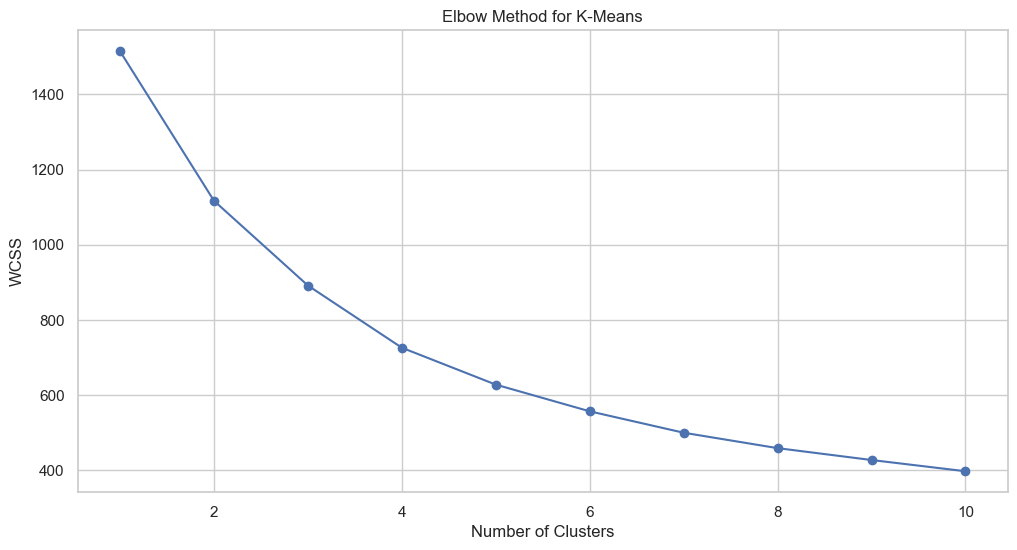

In [39]:
wcss = []

for k in range(1, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    wcss.append(model.inertia_)

plt.plot(
    range(1, 11),
    wcss,
    marker="o"
)

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")

plt.show()

Cell 21: Generate company performance rankings
Create a consolidated table of historical returns, volatility, trading activity and drawdowns.

In [42]:
# Combine company performance information

final_summary = performance.merge(
    volatility[
        ["Ticker", "Annualized_Volatility"]
    ],
    on="Ticker",
    how="left"
)

# Merge only the drawdown value to avoid duplicate columns
final_summary = final_summary.merge(
    drawdowns[
        ["Ticker", "Maximum_Drawdown"]
    ],
    on="Ticker",
    how="left"
)

# Add average trading volume
volume_data = df.groupby("Ticker")["volume"].mean().reset_index()

volume_data.rename(
    columns={"volume": "Average_Volume"},
    inplace=True
)

final_summary = final_summary.merge(
    volume_data,
    on="Ticker",
    how="left"
)

# Check final columns
print("Final Summary Columns:")
print(final_summary.columns.tolist())

display(final_summary.head())

Final Summary Columns:
['Ticker', 'Company_Name', 'First_Price', 'Last_Price', 'Trading_Days', 'Total_Return', 'Annualized_Volatility', 'Maximum_Drawdown', 'Average_Volume']


,Ticker,Company_Name,First_Price,Last_Price,Trading_Days,Total_Return,Annualized_Volatility,Maximum_Drawdown,Average_Volume
0,A,Agilent Technologies,45.0800,68.06,1259,50.976043,24.576606,-45.232234,2.338039e+06
1,AAL,AAL,14.7500,51.40,1259,248.474576,35.648394,-54.680775,9.390321e+06
2,AAP,AAP,78.9000,109.93,1259,39.328264,30.095112,-60.385268,1.078043e+06
3,AAPL,Apple Inc.,67.8542,159.54,1259,135.121776,23.165689,-32.075188,5.404790e+07
4,ABBV,AbbVie,36.2500,113.62,1259,213.434483,26.758557,-32.233609,7.870683e+06


Cell 22: Generate automatic project conclusions
Summarise the strongest historical performers, highest-risk stocks and strongest sectors.

In [43]:
# Identify the best-performing company
best_stock = final_summary.loc[
    final_summary["Total_Return"].idxmax()
]

# Identify the most volatile company
riskiest_stock = final_summary.loc[
    final_summary["Annualized_Volatility"].idxmax()
]

# Identify the company with the largest drawdown
worst_drawdown = final_summary.loc[
    final_summary["Maximum_Drawdown"].idxmin()
]

# Identify the best-performing sector
best_sector = sector_ranking.idxmax()

# Identify the worst-performing sector
worst_sector = sector_ranking.idxmin()

print("=" * 55)
print("       S&P 500 ANALYTICAL FINDINGS")
print("=" * 55)

print(
    f"\nBest historical performer: "
    f"{best_stock['Company_Name']} ({best_stock['Ticker']})"
)

print(
    f"Total price return: "
    f"{best_stock['Total_Return']:.2f}%"
)

print(
    f"\nHighest volatility: "
    f"{riskiest_stock['Company_Name']} "
    f"({riskiest_stock['Ticker']})"
)

print(
    f"Annualized volatility: "
    f"{riskiest_stock['Annualized_Volatility']:.2f}%"
)

print(
    f"\nLargest historical drawdown: "
    f"{worst_drawdown['Company_Name']} "
    f"({worst_drawdown['Ticker']})"
)

print(
    f"Maximum drawdown: "
    f"{worst_drawdown['Maximum_Drawdown']:.2f}%"
)

print(f"\nBest-performing sector: {best_sector}")

print(f"Sector cumulative return: {sector_ranking.max():.2f}%")

print(f"\nWorst-performing sector: {worst_sector}")

print(f"Sector cumulative return: {sector_ranking.min():.2f}%")

print("\nTotal companies analysed:", df["Ticker"].nunique())

print("Total historical records:", len(df))

print("=" * 55)

       S&P 500 ANALYTICAL FINDINGS

Best historical performer: Nvidia (NVDA)
Total price return: 1749.64%

Highest volatility: CHK (CHK)
Annualized volatility: 66.13%

Largest historical drawdown: CHK (CHK)
Maximum drawdown: -94.92%

Best-performing sector: Information Technology
Sector cumulative return: 178.67%

Worst-performing sector: Energy
Sector cumulative return: 8.40%

Total companies analysed: 505
Total historical records: 619040


In [44]:
# Create output folder
output_path = path / "Analysis_Results"

output_path.mkdir(exist_ok=True)

# Save cleaned stock data
df.to_csv(
    output_path / "cleaned_stock_data.csv",
    index=False
)

# Save company performance
final_summary.to_csv(
    output_path / "company_performance.csv",
    index=False
)

# Save sector performance
sector_ranking.to_csv(
    output_path / "sector_ranking.csv"
)

# Save correlation matrix
correlation.to_csv(
    output_path / "stock_correlation.csv"
)

# Save monthly market returns
monthly_data.to_csv(
    output_path / "monthly_market_returns.csv"
)

# Save clustering results
company_profile.to_csv(
    output_path / "company_clusters.csv"
)

print("All results exported successfully!")
print("Output folder:", output_path)

All results exported successfully!
Output folder: E:\LPU\Third Year\SEM5\Predictive Analysis\archive (2)\Analysis_Results


Section 1 — Next-month return prediction using Linear Regression

In [45]:

# Sort data chronologically for each stock
df = df.sort_values(["Ticker", "date"]).copy()

# Calculate daily returns
df["Daily_Return"] = df.groupby("Ticker")["close"].pct_change()

# Create historical input features
df["Return_5_Days"] = df.groupby("Ticker")["close"].pct_change(5)
df["Return_21_Days"] = df.groupby("Ticker")["close"].pct_change(21)

# Calculate rolling volatility
df["Volatility_21_Days"] = (
    df.groupby("Ticker")["Daily_Return"]
      .transform(lambda x: x.rolling(21).std())
)

# Calculate trading volume change
df["Volume_Change_5_Days"] = (
    df.groupby("Ticker")["volume"].pct_change(5)
)

# Target: return over the next 21 trading days
df["Next_21_Day_Return"] = (
    df.groupby("Ticker")["close"].shift(-21) / df["close"] - 1
)

# Select features
feature_cols = [
    "Return_5_Days",
    "Return_21_Days",
    "Volatility_21_Days",
    "Volume_Change_5_Days"
]

# Prepare model dataset
model_data = df[
    ["date", "Ticker", "Company_Name", "Next_21_Day_Return"] + feature_cols
].replace([np.inf, -np.inf], np.nan).dropna(
    subset=["Next_21_Day_Return"] + feature_cols
)

print("Prediction dataset shape:", model_data.shape)
display(model_data.head())

Prediction dataset shape: (597828, 8)


,date,Ticker,Company_Name,Next_21_Day_Return,Return_5_Days,Return_21_Days,Volatility_21_Days,Volume_Change_5_Days
21,2013-03-12,A,Agilent Technologies,0.029094,-0.000938,-0.054570,0.015483,0.145454
22,2013-03-13,A,Agilent Technologies,0.040698,-0.005550,-0.035874,0.015560,-0.252201
23,2013-03-14,A,Agilent Technologies,-0.006464,0.001618,-0.029135,0.015681,0.176630
24,2013-03-15,A,Agilent Technologies,0.008835,-0.000465,-0.038883,0.015700,-0.207785
25,2013-03-18,A,Agilent Technologies,-0.008461,-0.006073,-0.045536,0.015816,-0.662375


Splitiing the data chronologically

In [48]:
# Find the date separating training and testing data
unique_dates = sorted(model_data["date"].unique())

split_index = int(len(unique_dates) * 0.80)
split_date = unique_dates[split_index]

train_data = model_data[model_data["date"] < split_date]
test_data = model_data[model_data["date"] >= split_date]

X_train = train_data[feature_cols]
X_test = test_data[feature_cols]

y_train = train_data["Next_21_Day_Return"]
y_test = test_data["Next_21_Day_Return"]

print("Training records:", len(train_data))
print("Testing records:", len(test_data))
print("Split date:", split_date)

Training records: 475385
Testing records: 122443
Split date: 2017-01-20 00:00:00


In [49]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create and train the model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Predict test data
lr_predictions = lr_model.predict(X_test)

# Evaluate model
mae = mean_absolute_error(y_test, lr_predictions)
rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
r2 = r2_score(y_test, lr_predictions)

print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

LINEAR REGRESSION RESULTS
-------------------------
MAE: 0.0482
RMSE: 0.0652
R2 Score: -0.0117


Predict the next 21 trading days for each stock

In [50]:
# Get the latest feature record for every stock
latest_data = (
    df.sort_values("date")
      .groupby("Ticker")
      .tail(1)
      .dropna(subset=feature_cols)
      .copy()
)

# Predict next 21-day returns
latest_data["Predicted_21_Day_Return"] = lr_model.predict(
    latest_data[feature_cols]
)

# Convert predicted returns into percentages
latest_data["Predicted_Return_Percentage"] = (
    latest_data["Predicted_21_Day_Return"] * 100
)

# Display top predicted returns
prediction_results = latest_data[
    ["Ticker", "Company_Name", "date", "Predicted_Return_Percentage"]
].sort_values(
    "Predicted_Return_Percentage", ascending=False
)

print("TOP 10 PREDICTED STOCK RETURNS")
display(prediction_results.head(10))

TOP 10 PREDICTED STOCK RETURNS


,Ticker,Company_Name,date,Predicted_Return_Percentage
425150,NWL,NWL,2018-02-07,4.355488
116818,CHK,CHK,2018-02-07,4.329545
494374,RRC,RRC,2018-02-07,3.979057
71610,AYI,AYI,2018-02-07,3.856260
41350,AMD,Advanced Micro Devices,2018-02-07,3.593600
261354,GWW,W. W. Grainger,2018-02-07,3.554763
353686,LRCX,Lam Research,2018-02-07,3.533135
556158,UA,UA,2018-02-07,3.519810
399010,MU,Micron Technology,2018-02-07,3.479253
83236,BHGE,BHGE,2018-02-07,3.315743


Stock direction prediction using Logistic Regression

In [54]:

# Positive return = 1, negative or zero return = 0
classification_data = model_data.copy()

classification_data["Market_Direction"] = (
    classification_data["Next_21_Day_Return"] > 0
).astype(int)

# Use the same chronological split date
train_class = classification_data[
    classification_data["date"] < split_date
]

test_class = classification_data[
    classification_data["date"] >= split_date
]

X_train_class = train_class[feature_cols]
X_test_class = test_class[feature_cols]

y_train_class = train_class["Market_Direction"]
y_test_class = test_class["Market_Direction"]

print("Training records:", len(train_class))
print("Testing records:", len(test_class))

Training records: 475385
Testing records: 122443


In [55]:

# Create and train the model
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_class, y_train_class)

# Predict stock direction
direction_predictions = log_model.predict(X_test_class)

# Evaluate model
print("LOGISTIC REGRESSION RESULTS")
print("---------------------------")
print("Accuracy:", round(accuracy_score(y_test_class, direction_predictions), 4))
print("Precision:", round(precision_score(y_test_class, direction_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test_class, direction_predictions, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test_class, direction_predictions, zero_division=0), 4))

print("\nClassification Report:")
print(classification_report(y_test_class, direction_predictions, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test_class, direction_predictions))

LOGISTIC REGRESSION RESULTS
---------------------------
Accuracy: 0.6161
Precision: 0.6161
Recall: 0.9999
F1 Score: 0.7624

Classification Report:
              precision    recall  f1-score   support

           0       0.42      0.00      0.00     47006
           1       0.62      1.00      0.76     75437

    accuracy                           0.62    122443
   macro avg       0.52      0.50      0.38    122443
weighted avg       0.54      0.62      0.47    122443

Confusion Matrix:
[[    8 46998]
 [   11 75426]]


In [56]:
# Predict probability of a positive return
latest_data["Probability_Of_Rise"] = (
    log_model.predict_proba(latest_data[feature_cols])[:, 1] * 100
)

latest_data["Predicted_Direction"] = np.where(
    latest_data["Probability_Of_Rise"] >= 50,
    "Positive",
    "Negative"
)

direction_results = latest_data[
    ["Ticker", "Company_Name", "Probability_Of_Rise", "Predicted_Direction"]
].sort_values(
    "Probability_Of_Rise", ascending=False
)

print("STOCK DIRECTION PREDICTIONS")
display(direction_results.head(10))

STOCK DIRECTION PREDICTIONS


,Ticker,Company_Name,Probability_Of_Rise,Predicted_Direction
116818,CHK,CHK,66.657335,Positive
494374,RRC,RRC,65.895900,Positive
425150,NWL,NWL,65.773748,Positive
71610,AYI,AYI,65.562238,Positive
556158,UA,UA,64.495795,Positive
500669,SCG,SCG,64.004653,Positive
557417,UAA,UAA,63.899362,Positive
83236,BHGE,BHGE,63.863881,Positive
353686,LRCX,Lam Research,63.816032,Positive
32733,ALB,Albemarle Corporation,63.811615,Positive


Calculate optimistic, normal and pessimistic returns

Section 3 — What-if market scenarios
Cell 8 — Calculate optimistic, normal and pessimistic returns

In [59]:
# Calculate historical 21-day return percentiles
pessimistic_return = model_data["Next_21_Day_Return"].quantile(0.10)
normal_return = model_data["Next_21_Day_Return"].median()
optimistic_return = model_data["Next_21_Day_Return"].quantile(0.90)

investment = 10000

# Calculate possible investment values
scenario_results = pd.DataFrame({
    "Scenario": ["Pessimistic", "Normal", "Optimistic"],
    "Assumed_Return": [
        pessimistic_return,
        normal_return,
        optimistic_return
    ]
})

scenario_results["Return_Percentage"] = (
    scenario_results["Assumed_Return"] * 100
)

scenario_results["Initial_Investment"] = investment

scenario_results["Estimated_Value"] = (
    investment * (1 + scenario_results["Assumed_Return"])
)

scenario_results["Profit_or_Loss"] = (
    scenario_results["Estimated_Value"] - investment
)

print("21-DAY INVESTMENT SCENARIOS")
display(scenario_results.round(2))

21-DAY INVESTMENT SCENARIOS


,Scenario,Assumed_Return,Return_Percentage,Initial_Investment,Estimated_Value,Profit_or_Loss
0,Pessimistic,-0.07,-6.78,10000,9321.96,-678.04
1,Normal,0.01,1.16,10000,10116.45,116.45
2,Optimistic,0.09,9.02,10000,10902.18,902.18


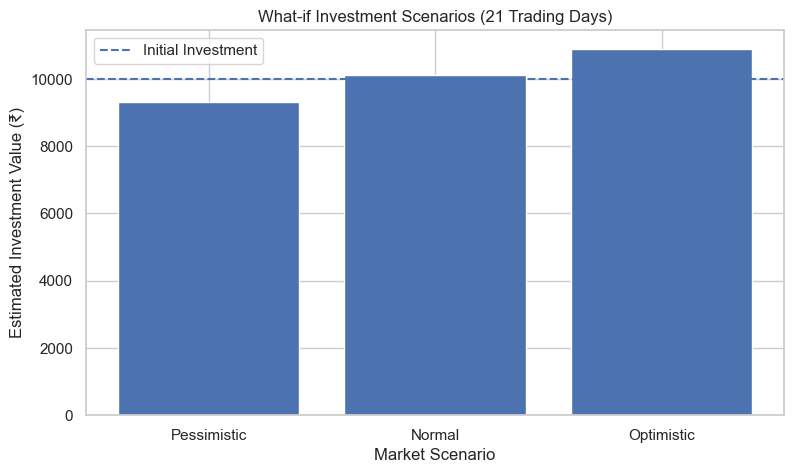

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    scenario_results["Scenario"],
    scenario_results["Estimated_Value"]
)

plt.axhline(
    investment,
    linestyle="--",
    label="Initial Investment"
)

plt.title("What-if Investment Scenarios (21 Trading Days)")
plt.xlabel("Market Scenario")
plt.ylabel("Estimated Investment Value (₹)")
plt.legend()
plt.show()